In [4]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Set random seeds
np.random.seed(42)
tf.random.set_seed(42)

from sklearn.datasets import fetch_openml

# ==========================================
# 1. LOAD REAL-WORLD BANKING DATASET (OPENML)
# ==========================================
print("Fetching dataset...")
bank_data = fetch_openml(data_id=43390, as_frame=True, parser="auto")
df = bank_data.frame

# Ensure target and numeric columns have the right data types
df["Exited"] = df["Exited"].astype(int)
numeric_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "HasCrCard", "IsActiveMember", "EstimatedSalary"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col])

# Drop identifier columns if present
cols_to_drop = [c for c in ["RowNumber", "CustomerId", "Surname"] if c in df.columns]
df = df.drop(columns=cols_to_drop)

# Target 1: Actual Customer Churn
y_churn = df["Exited"].values

# Target 2: Engineered 12-Month CLV Proxy ($)
retained_multiplier = np.where(y_churn == 1, 0.25, 1.0)
y_clv = (
    (df["Balance"] * 0.015) + 
    (df["NumOfProducts"] * 120) + 
    (df["EstimatedSalary"] * 0.005)
) * retained_multiplier

# Separate input features
X = df.drop(columns=["Exited"])


# ==========================================
# 2. PREPROCESS MIXED FEATURES (NUMERIC + TEXT)
# ==========================================
numeric_features = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "HasCrCard", "IsActiveMember", "EstimatedSalary"]
categorical_features = ["Geography", "Gender"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(drop="first", sparse_output=False), categorical_features)
    ]
)

X_train, X_test, y_churn_train, y_churn_test, y_clv_train, y_clv_test = train_test_split(
    X, y_churn, y_clv, test_size=0.2, random_state=42, stratify=y_churn
)

# Fit preprocessor ONLY on training data to prevent data leakage
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# ==========================================
# 3. BUILD MULTI-TASK MODEL (FUNCTIONAL API)
# ==========================================
inputs = tf.keras.Input(shape=(X_train_processed.shape[1],), name="bank_features")

# Deeper shared network with BatchNormalization for real-world noise
shared = tf.keras.layers.Dense(128, activation="relu")(inputs)
shared = tf.keras.layers.BatchNormalization()(shared)
shared = tf.keras.layers.Dropout(0.3)(shared)
shared = tf.keras.layers.Dense(64, activation="relu")(shared)

# Branch 1: Churn Probability
churn_branch = tf.keras.layers.Dense(32, activation="relu")(shared)
churn_output = tf.keras.layers.Dense(1, activation="sigmoid", name="churn_output")(churn_branch)

# Branch 2: Predicted CLV ($)
clv_branch = tf.keras.layers.Dense(32, activation="relu")(shared)
clv_output = tf.keras.layers.Dense(1, activation="linear", name="clv_output")(clv_branch)

model = tf.keras.Model(inputs=inputs, outputs=[churn_output, clv_output])

# ==========================================
# 4. COMPILE WITH LOSS WEIGHTING & AUC
# ==========================================
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.002),
    loss={
        "churn_output": "binary_crossentropy",
        "clv_output": "mse"
    },
    loss_weights={
        "churn_output": 1.0,
        "clv_output": 0.00005  # Scaled down to match binary_crossentropy magnitude
    },
    metrics={
        "churn_output": ["accuracy", tf.keras.metrics.AUC(name="auc")],
        "clv_output": ["mae"]
    }
)

# ==========================================
# 5. TRAIN WITH EARLY STOPPING
# ==========================================
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=8, restore_best_weights=True
)

print("Training on real banking dataset...")
history = model.fit(
    X_train_processed,
    {"churn_output": y_churn_train, "clv_output": y_clv_train},
    validation_split=0.2,
    epochs=60,
    batch_size=64,
    callbacks=[early_stop],
    verbose=0
)
print(f"Stopped at epoch {len(history.history['loss'])}\n")

import joblib

# 1. Save the trained TensorFlow model using the modern .keras format
model.save("churn_clv_model.keras")

# 2. Save the fitted ColumnTransformer preprocessor
joblib.dump(preprocessor, "bank_preprocessor.joblib")

print("Saved model and preprocessor successfully!")


# ==========================================
# 6. EVALUATE & INSPECT SAMPLE CUSTOMERS
# ==========================================
results = model.evaluate(
    X_test_processed,
    {"churn_output": y_churn_test, "clv_output": y_clv_test},
    verbose=0
)

# Output indices match compiled metrics order
print(f"Test Churn Accuracy: {results[3]*100:.2f}%")
print(f"Test Churn ROC-AUC:  {results[4]:.3f}")
print(f"Test CLV MAE:        ${results[5]:.2f}\n")

# Predict on the first 5 customers from the test set
sample_X = X_test_processed[:5]
pred_churn, pred_clv = model.predict(sample_X, verbose=0)

print("--- Sample Test Set Predictions ---")
for i in range(5):
    actual_status = "Churned" if y_churn_test[i] == 1 else "Stayed"
    print(
        f"Customer {i+1} ({actual_status}): "
        f"Pred Churn = {pred_churn[i][0]*100:.1f}% | "
        f"Pred CLV = ${pred_clv[i][0]:.2f} (Actual: ${y_clv_test.iloc[i]:.2f})"
    )


Fetching dataset...
Training on real banking dataset...
Stopped at epoch 35

Saved model and preprocessor successfully!
Test Churn Accuracy: 86.35%
Test Churn ROC-AUC:  0.850
Test CLV MAE:        $319.25

--- Sample Test Set Predictions ---
Customer 1 (Stayed): Pred Churn = 1.2% | Pred CLV = $769.93 (Actual: $711.42)
Customer 2 (Stayed): Pred Churn = 5.2% | Pred CLV = $2519.64 (Actual: $2480.72)
Customer 3 (Stayed): Pred Churn = 2.0% | Pred CLV = $703.30 (Actual: $767.17)
Customer 4 (Stayed): Pred Churn = 5.3% | Pred CLV = $2487.86 (Actual: $2500.65)
Customer 5 (Stayed): Pred Churn = 16.4% | Pred CLV = $1877.14 (Actual: $2130.13)


In [3]:
# ==========================================
# 7. BUILD RISK-MATRIX PRIORITIZATION TABLE
# ==========================================
# Generate predictions for the entire test set
all_pred_churn, all_pred_clv = model.predict(X_test_processed, verbose=0)

# Create a results DataFrame aligned with original customer features
risk_df = X_test.copy()
risk_df["Churn_Prob"] = all_pred_churn.flatten()
risk_df["Predicted_CLV"] = np.maximum(all_pred_clv.flatten(), 0) # Floor at $0

# Expected Revenue at Risk = Probability of leaving * Value of customer
risk_df["Revenue_At_Risk"] = risk_df["Churn_Prob"] * risk_df["Predicted_CLV"]

# Define thresholds (50% churn risk & median CLV of the test set)
churn_threshold = 0.50
clv_threshold = risk_df["Predicted_CLV"].median()

# Assign each customer to a prioritization quadrant
conditions = [
    (risk_df["Churn_Prob"] >= churn_threshold) & (risk_df["Predicted_CLV"] >= clv_threshold),
    (risk_df["Churn_Prob"] >= churn_threshold) & (risk_df["Predicted_CLV"] < clv_threshold),
    (risk_df["Churn_Prob"] < churn_threshold)  & (risk_df["Predicted_CLV"] >= clv_threshold),
    (risk_df["Churn_Prob"] < churn_threshold)  & (risk_df["Predicted_CLV"] < clv_threshold)
]

tiers = [
    "1. VIP Rescue (High Risk / High CLV)",
    "2. Automated Win-Back (High Risk / Low CLV)",
    "3. VIP Nurture (Low Risk / High CLV)",
    "4. Standard Monitor (Low Risk / Low CLV)"
]

risk_df["Priority_Tier"] = np.select(conditions, tiers, default="Unassigned")

# --- SUMMARY REPORT BY QUADRANT ---
summary = risk_df.groupby("Priority_Tier").agg(
    Customer_Count=("Churn_Prob", "count"),
    Avg_Churn_Risk=("Churn_Prob", "mean"),
    Total_CLV=("Predicted_CLV", "sum"),
    Total_Revenue_At_Risk=("Revenue_At_Risk", "sum")
).reset_index()

print("--- RETENTION PORTFOLIO SUMMARY ---")
print(summary.to_string(index=False, formatters={
    "Avg_Churn_Risk": "{:.1%}".format,
    "Total_CLV": "${:,.2f}".format,
    "Total_Revenue_At_Risk": "${:,.2f}".format
}))

# --- TOP 10 INDIVIDUAL CUSTOMERS TO CALL TODAY ---
top_targets = risk_df[risk_df["Priority_Tier"] == "1. VIP Rescue (High Risk / High CLV)"]
top_targets = top_targets.sort_values(by="Revenue_At_Risk", ascending=False).head(10)

print("\n--- TOP 10 VIP RESCUE TARGETS ---")
cols_to_show = ["Geography", "Age", "Balance", "NumOfProducts", "Churn_Prob", "Predicted_CLV", "Revenue_At_Risk"]
print(top_targets[cols_to_show].to_string(index=False, formatters={
    "Balance": "${:,.2f}".format,
    "Churn_Prob": "{:.1%}".format,
    "Predicted_CLV": "${:,.2f}".format,
    "Revenue_At_Risk": "${:,.2f}".format
}))


--- RETENTION PORTFOLIO SUMMARY ---
                              Priority_Tier  Customer_Count Avg_Churn_Risk     Total_CLV Total_Revenue_At_Risk
       1. VIP Rescue (High Risk / High CLV)              33          61.4%    $60,981.48            $37,354.36
2. Automated Win-Back (High Risk / Low CLV)             197          74.1%   $162,073.73           $116,523.18
       3. VIP Nurture (Low Risk / High CLV)             967          14.8% $2,261,069.00           $312,678.72
   4. Standard Monitor (Low Risk / Low CLV)             803          10.3%   $618,836.75            $72,828.50

--- TOP 10 VIP RESCUE TARGETS ---
Geography  Age     Balance  NumOfProducts Churn_Prob Predicted_CLV Revenue_At_Risk
    Spain   38 $250,898.09              3      99.6%     $1,954.67       $1,946.68
  Germany   40 $164,948.98              3      83.9%     $2,004.45       $1,682.22
    Spain   53 $187,602.18              1      66.3%     $2,404.13       $1,594.99
  Germany   57 $163,146.46              1 

In [7]:
import joblib
import numpy as np
import pandas as pd
import tensorflow as tf

# ==========================================
# 1. LOAD SAVED MODEL & PREPROCESSOR
# ==========================================
loaded_model = tf.keras.models.load_model("churn_clv_model.keras")
loaded_preprocessor = joblib.load("bank_preprocessor.joblib")

# ==========================================
# 2. SIMULATE NEW MONTHLY CUSTOMER DATA
# ==========================================
new_month_customers = pd.DataFrame({
    "CreditScore": [615, 720],
    "Geography": ["Germany", "France"],
    "Gender": ["Female", "Male"],
    "Age": [48, 35],
    "Tenure": [3, 7],
    "Balance": [145000.00, 52000.00],
    "NumOfProducts": [1, 2],
    "HasCrCard": [1, 1],
    "IsActiveMember": [0, 1],
    "EstimatedSalary": [95000.00, 110000.00]
})


# ==========================================
# 3. TRANSFORM & PREDICT
# ==========================================
# Use .transform() ONLY — never call .fit_transform() on new data
new_X_processed = loaded_preprocessor.transform(new_month_customers)

pred_churn, pred_clv = loaded_model.predict(new_X_processed, verbose=0)

# Attach predictions back to the table
new_month_customers["Churn_Prob"] = pred_churn.flatten()
new_month_customers["Predicted_CLV"] = np.maximum(pred_clv.flatten(), 0)
new_month_customers["Revenue_At_Risk"] = (
    new_month_customers["Churn_Prob"] * new_month_customers["Predicted_CLV"]
)

print(new_month_customers[["Geography", "Age", "Balance", "Churn_Prob", "Predicted_CLV", "Revenue_At_Risk"]])


  Geography  Age   Balance  Churn_Prob  Predicted_CLV  Revenue_At_Risk
0   Germany   48  145000.0    0.757399    1384.598389      1048.693481
1    France   35   52000.0    0.089561    1478.054810       132.376205


In [9]:
import requests

# Use the full localhost IP, port 8000, and the /predict route
url = "http://localhost:8000/predict"

sample_customer = {
    "CreditScore": 615,
    "Geography": "Germany",
    "Gender": "Female",
    "Age": 48,
    "Tenure": 3,
    "Balance": 145000.00,
    "NumOfProducts": 1,
    "HasCrCard": 1,
    "IsActiveMember": 0,
    "EstimatedSalary": 95000.00
}

response = requests.post(url, json=sample_customer)
print(response.json())


{'churn_probability': 0.7574, 'predicted_clv_usd': 1384.6, 'revenue_at_risk_usd': 1048.69, 'priority_tier': '1. VIP Rescue'}


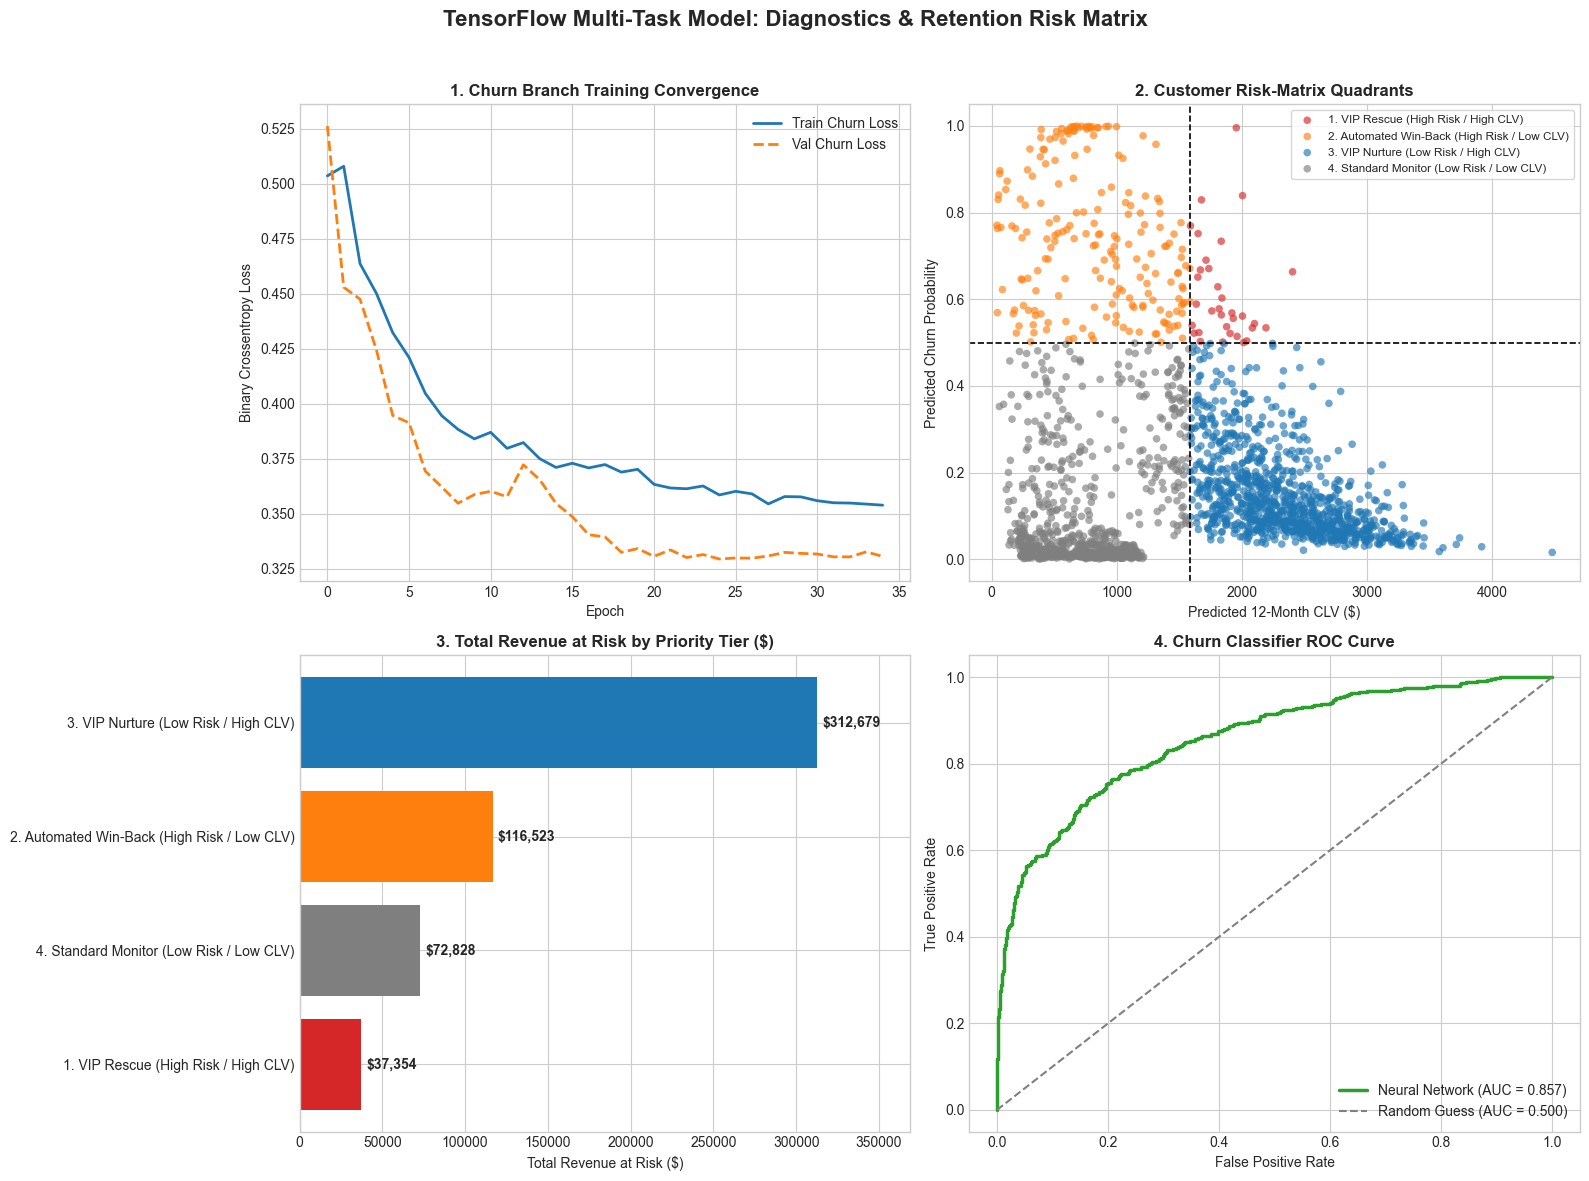

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Set a clean, modern visual style
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("TensorFlow Multi-Task Model: Diagnostics & Retention Risk Matrix", fontsize=16, fontweight="bold")

# ---------------------------------------------------------
# 1. TRAINING VS. VALIDATION LOSS (CHURN BRANCH)
# ---------------------------------------------------------
ax1 = axes[0, 0]
ax1.plot(history.history["churn_output_loss"], label="Train Churn Loss", linewidth=2)
ax1.plot(history.history["val_churn_output_loss"], label="Val Churn Loss", linestyle="--", linewidth=2)
ax1.set_title("1. Churn Branch Training Convergence", fontsize=12, fontweight="bold")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Binary Crossentropy Loss")
ax1.legend()

# ---------------------------------------------------------
# 2. RISK-MATRIX QUADRANT SCATTER PLOT
# ---------------------------------------------------------
ax2 = axes[0, 1]
colors = {
    "1. VIP Rescue (High Risk / High CLV)": "#d62728",      # Red
    "2. Automated Win-Back (High Risk / Low CLV)": "#ff7f0e", # Orange
    "3. VIP Nurture (Low Risk / High CLV)": "#1f77b4",       # Blue
    "4. Standard Monitor (Low Risk / Low CLV)": "#7f7f7f"    # Gray
}

for tier, color in colors.items():
    subset = risk_df[risk_df["Priority_Tier"] == tier]
    ax2.scatter(
        subset["Predicted_CLV"], subset["Churn_Prob"],
        c=color, label=tier, alpha=0.65, edgecolors="none", s=30
    )

# Add threshold divider lines
ax2.axhline(0.50, color="black", linestyle="--", linewidth=1.2)
ax2.axvline(risk_df["Predicted_CLV"].median(), color="black", linestyle="--", linewidth=1.2)
ax2.set_title("2. Customer Risk-Matrix Quadrants", fontsize=12, fontweight="bold")
ax2.set_xlabel("Predicted 12-Month CLV ($)")
ax2.set_ylabel("Predicted Churn Probability")
ax2.legend(loc="upper right", fontsize=8.5, frameon=True)

# ---------------------------------------------------------
# 3. TOTAL REVENUE AT RISK BY PRIORITY TIER
# ---------------------------------------------------------
ax3 = axes[1, 0]
tier_risk = risk_df.groupby("Priority_Tier")["Revenue_At_Risk"].sum().sort_values()
bar_colors = [colors[t] for t in tier_risk.index]

bars = ax3.barh(tier_risk.index, tier_risk.values, color=bar_colors)
ax3.set_title("3. Total Revenue at Risk by Priority Tier ($)", fontsize=12, fontweight="bold")
ax3.set_xlabel("Total Revenue at Risk ($)")

# Add dollar labels next to bars
for bar in bars:
    width = bar.get_width()
    ax3.text(width + (tier_risk.max() * 0.01), bar.get_y() + bar.get_height()/2,
             f"${width:,.0f}", va="center", fontsize=10, fontweight="bold")
ax3.set_xlim(0, tier_risk.max() * 1.18)

# ---------------------------------------------------------
# 4. ROC CURVE FOR CHURN CLASSIFICATION
# ---------------------------------------------------------
ax4 = axes[1, 1]
fpr, tpr, _ = roc_curve(y_churn_test, risk_df["Churn_Prob"])
roc_auc = auc(fpr, tpr)

ax4.plot(fpr, tpr, color="#2ca02c", linewidth=2.5, label=f"Neural Network (AUC = {roc_auc:.3f})")
ax4.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random Guess (AUC = 0.500)")
ax4.set_title("4. Churn Classifier ROC Curve", fontsize=12, fontweight="bold")
ax4.set_xlabel("False Positive Rate")
ax4.set_ylabel("True Positive Rate")
ax4.legend(loc="lower right")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("model_diagnostics_dashboard.png", dpi=300)
plt.show()


In [11]:
# Add a clean Customer ID for tracking in Power BI
risk_df = risk_df.reset_index(drop=True)
risk_df["Customer_ID"] = ["CUST-" + str(10001 + i) for i in range(len(risk_df))]

# Reorder columns so key metrics appear first
export_cols = [
    "Customer_ID", "Priority_Tier", "Churn_Prob", "Predicted_CLV", 
    "Revenue_At_Risk", "Geography", "Gender", "Age", "Tenure", 
    "Balance", "NumOfProducts", "HasCrCard", "IsActiveMember", "EstimatedSalary"
]

# Export to CSV without the pandas row index
risk_df[export_cols].to_csv("bank_churn_clv_predictions.csv", index=False)
print("Exported bank_churn_clv_predictions.csv successfully!")


Exported bank_churn_clv_predictions.csv successfully!
